<a href="https://colab.research.google.com/github/emmanueloni570-hub/Oluwasegun_INFO4670_Fall2026-/blob/main/INFO4670_Assignment_SMS_Spam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [17]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> A false positive can be especially costly because a legitimate message—such as a bank fraud alert, medical appointment reminder, or one-time login code—could be blocked and cause the user to miss important information. A false negative also has a real cost: a spam or phishing message can reach the user and potentially lead to financial loss or stolen account information. For this carrier scenario, I consider false positives slightly more costly because blocking a legitimate message can prevent a user from receiving time-sensitive information without knowing it was filtered. The system should still catch as much spam as possible, so the trade-off needs to be monitored.

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
> I would use Precision as the primary metric because it measures the proportion of messages classified as spam that are actually spam. Higher precision reduces false positives, which helps prevent legitimate messages from being incorrectly blocked. I would still monitor recall so that the filter does not allow too much spam through.

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> A model that always predicts ham would achieve about 87% accuracy because roughly 87% of the messages are legitimate. That accuracy is misleading because the model would identify none of the spam messages: its spam recall and F1-score would both be zero. This shows why accuracy alone is not an appropriate measure for an imbalanced classification problem.

---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [18]:
import urllib.request, zipfile, io

# Current official UCI download location for the SMS Spam Collection.
url = 'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(
            f, sep='\t', header=None, names=['label', 'message'],
            encoding='latin-1'
        )

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)

Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


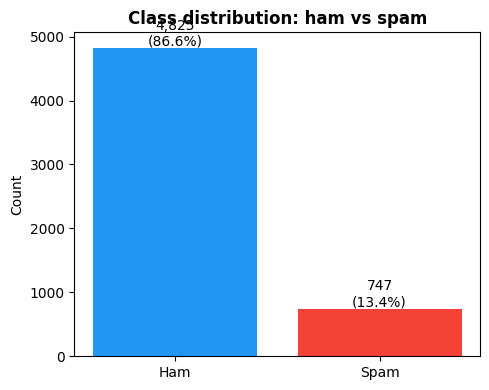

In [19]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [20]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea Â£900 prize reward! To claim call 09061701461. Claim code

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 72 characters
  Spam : 139 characters


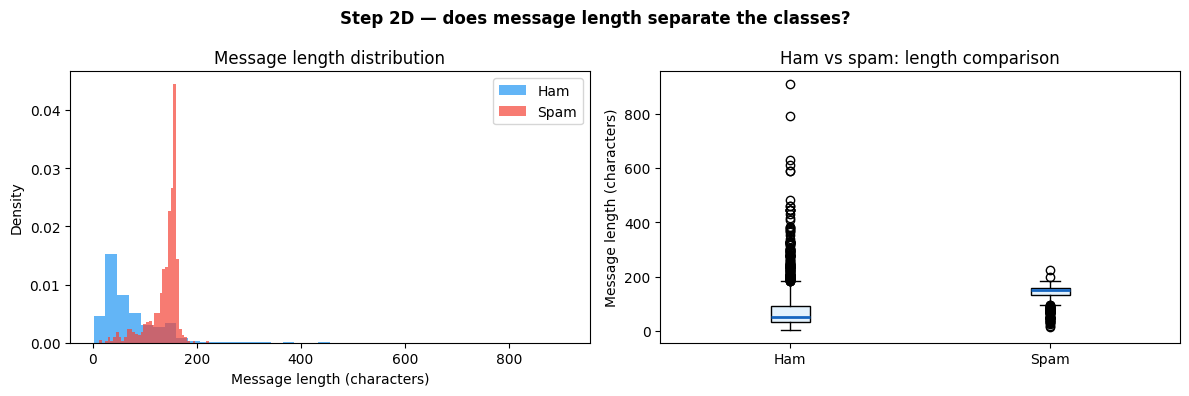

In [21]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [22]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.0%    0.1%  +55.0%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            77.4%   14.2%  +63.2%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [23]:
# Add two binary text features that differ from the four starter features.
def build_features_v2(df):
    d = build_features(df)   # keeps all 4 starter features
    msg = d['message'].str.lower()

    # Feature 5: contains a web address or URL-like string.
    d['has_url'] = msg.str.contains(
        r'(https?://|www\.|\b[a-z0-9-]+\.(com|net|org|info|biz)\b)',
        regex=True
    ).astype(int)

    # Feature 6: contains common promotional/selection language.
    d['has_promo_language'] = msg.str.contains(
        r'\b(guaranteed|selected|congratulations|congrats|'
        r'voucher|claim your|you have been chosen)\b',
        regex=True
    ).astype(int)

    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

# Print spam vs ham rate for all features
print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
for feat in feature_cols:
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')

All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.0%    0.1%  +55.0%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                77.4%   14.2%  +63.2%
has_url                16.6%    0.3%  +16.3%
has_promo_language     15.1%    0.3%  +14.8%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


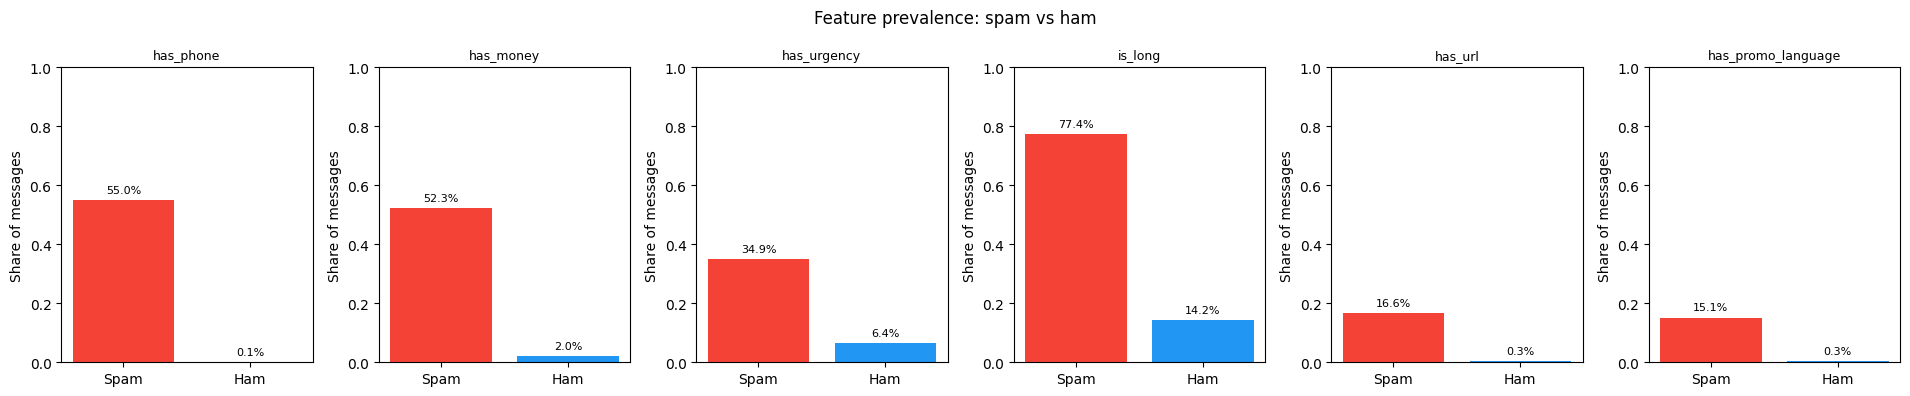

In [24]:
# Compare the prevalence of every binary feature in spam and ham messages.
n_features = len(feature_cols)
fig, axes = plt.subplots(1, n_features, figsize=(3.2*n_features, 4), squeeze=False)
for ax, feat in zip(axes.ravel(), feature_cols):
    spam_rate_feat = df.loc[df['spam'] == 1, feat].mean()
    ham_rate_feat = df.loc[df['spam'] == 0, feat].mean()
    ax.bar(['Spam', 'Ham'], [spam_rate_feat, ham_rate_feat],
           color=['#F44336', '#2196F3'])
    ax.set_title(feat, fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_ylabel('Share of messages')
    for j, value in enumerate([spam_rate_feat, ham_rate_feat]):
        ax.text(j, value + 0.025, f'{value:.1%}', ha='center', fontsize=8)
plt.suptitle('Feature prevalence: spam vs ham')
plt.tight_layout()
plt.show()

### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — name and explanation:*
> `has_url` identifies messages containing a web address, including strings beginning with http/https, `www.`, or common domain endings. I expected it to help because promotional and phishing messages often direct recipients to a website to claim an offer or provide information.

*Feature 2 — name and explanation:*
> `has_promo_language` identifies phrases such as “guaranteed,” “selected,” “congratulations,” “voucher,” and “claim your.” I expected these phrases to be useful because unsolicited prize and promotional messages often use this language to persuade recipients to respond.

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
> The feature with the largest spam–ham rate gap is the one with the greatest absolute difference between the percentage of spam messages containing it and the percentage of ham messages containing it. I will identify the exact feature from the Step 3B rate table after the notebook runs. A large gap suggests that the feature separates the two classes well. A Decision Tree can choose such a feature near its root because a split that makes the resulting groups more class-pure can provide greater Information Gain (a larger reduction in uncertainty/entropy).

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
> A realistic message that could evade these features is a short, plain-language phishing text such as “Your account needs attention. Sign in to review your recent activity.” If it contains no URL, phone number, money/prize term, urgency term, or promotional phrase from the feature patterns, the engineered features may all be zero. This illustrates that keyword and pattern features cannot recognize every harmful message, especially when the sender uses neutral language or a URL is omitted from the message.

---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [25]:
# Create the feature matrix and target, then make a stratified 75/25 split.
X = df[feature_cols].values
y = df['spam'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f'Training rows: {len(X_train):,}')
print(f'Test rows:     {len(X_test):,}')
print(f'Training spam rate: {y_train.mean():.1%}')
print(f'Test spam rate:     {y_test.mean():.1%}')

Training rows: 4,179
Test rows:     1,393
Training spam rate: 13.4%
Test spam rate:     13.4%


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> `stratify=y` keeps approximately the same proportion of spam and ham messages in both the training and test sets as in the full dataset. Without stratification, a random split could contain too few spam messages in one set, especially because spam is the minority class. That could make training less representative and make the evaluation metrics unstable or misleading.

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> I would prefer cross-validation when the dataset is relatively small and I want a more stable estimate of how the model performs. It evaluates the model across several different train/validation partitions, so the result depends less on one particular random split. It is especially useful when comparing models or tuning settings before selecting a final model.

---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Decision Tree leaves: 14


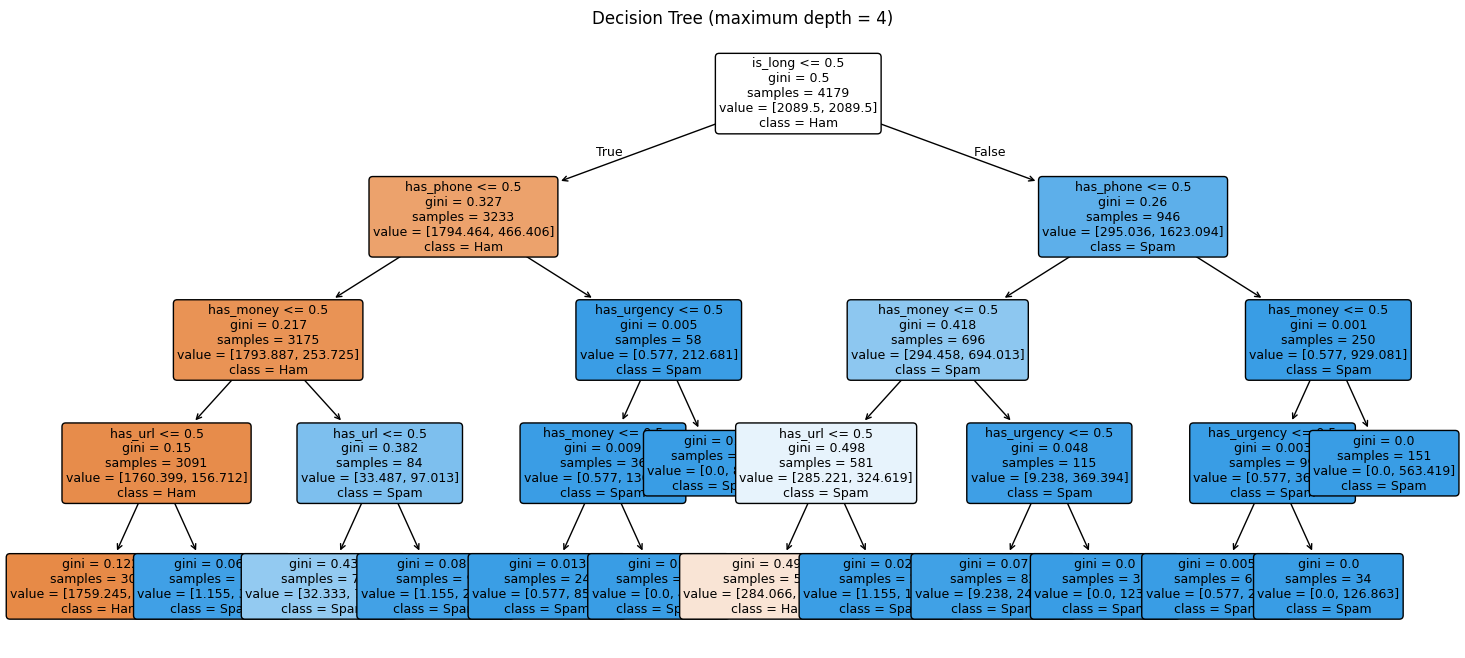

Decision Tree rules:
|--- is_long <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_money >  0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_urgency <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_urgency >  0.50
|   |   |   |--- class: 1
|--- is_long >  0.50
|   |--- has_phone <= 0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_money >  0.50
|   |   |   |--- has_urgency <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_urgency >  0.50
|   |   |   |   |--- class: 

In [26]:
# Train and inspect a class-balanced Decision Tree.
dt_model = DecisionTreeClassifier(
    max_depth=4, random_state=42, class_weight='balanced'
)
dt_model.fit(X_train, y_train)

print('Decision Tree leaves:', dt_model.get_n_leaves())
plt.figure(figsize=(18, 8))
plot_tree(
    dt_model, feature_names=feature_cols,
    class_names=['Ham', 'Spam'], filled=True, rounded=True,
    fontsize=9
)
plt.title('Decision Tree (maximum depth = 4)')
plt.show()

print('Decision Tree rules:')
print(export_text(dt_model, feature_names=feature_cols))

### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


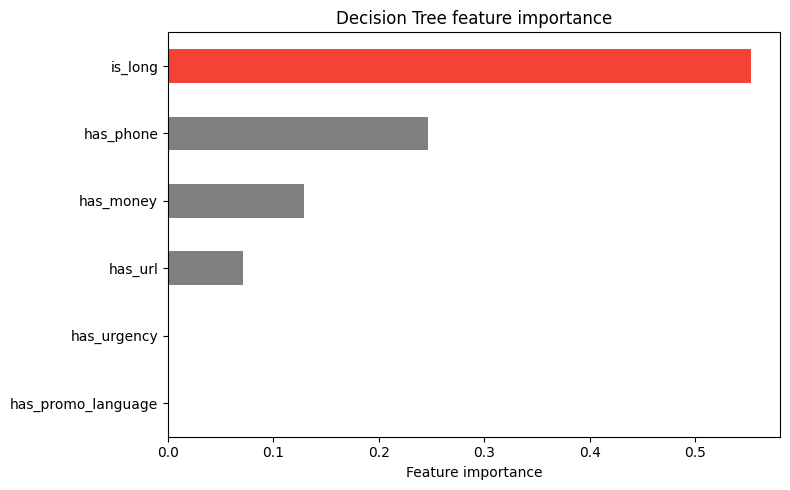

Most important feature: is_long


In [27]:
# Rank features by the Decision Tree's learned importance.
importance = pd.Series(
    dt_model.feature_importances_, index=feature_cols
).sort_values()
bar_colors = ['#F44336' if value == importance.max() else 'gray'
              for value in importance]
ax = importance.plot(kind='barh', color=bar_colors, figsize=(8, 5))
ax.set_xlabel('Feature importance')
ax.set_title('Decision Tree feature importance')
plt.tight_layout()
plt.show()
print('Most important feature:', importance.idxmax())

### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


depth  train_f1  test_f1
    1  0.577689 0.567460
    2  0.629156 0.620952
    3  0.628641 0.623853
    4  0.843722 0.823848
    5  0.823430 0.824742
    6  0.826712 0.824742
 None  0.826712 0.824742


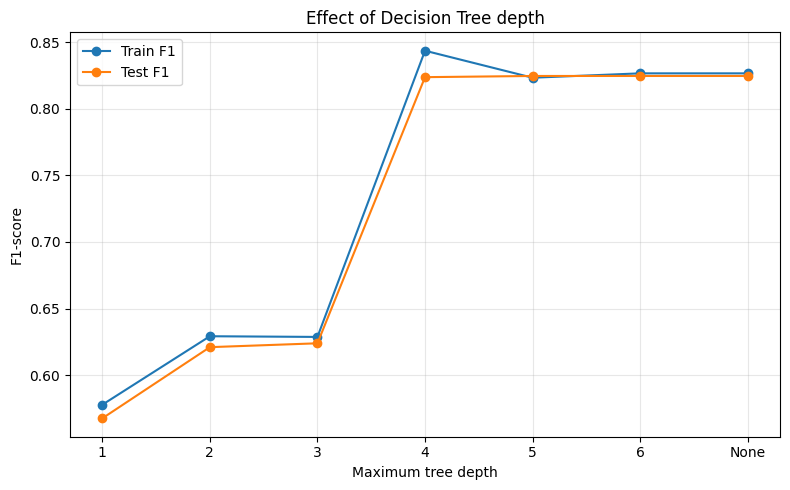

In [28]:
# Compare train and test F1 as tree depth increases.
depths = [1, 2, 3, 4, 5, 6, None]
depth_results = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth, random_state=42, class_weight='balanced'
    )
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    depth_results.append({
        'depth': 'None' if depth is None else str(depth),
        'train_f1': f1_score(y_train, train_pred, zero_division=0),
        'test_f1': f1_score(y_test, test_pred, zero_division=0)
    })

depth_df = pd.DataFrame(depth_results)
print(depth_df.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(depth_df['depth'], depth_df['train_f1'], marker='o', label='Train F1')
plt.plot(depth_df['depth'], depth_df['test_f1'], marker='o', label='Test F1')
plt.xlabel('Maximum tree depth')
plt.ylabel('F1-score')
plt.title('Effect of Decision Tree depth')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [29]:
# Train the Bernoulli Naive Bayes classifier on binary features.
nb_model = BernoulliNB()
nb_model.fit(X_train, y_train)
print('Bernoulli Naive Bayes training complete.')

Bernoulli Naive Bayes training complete.


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


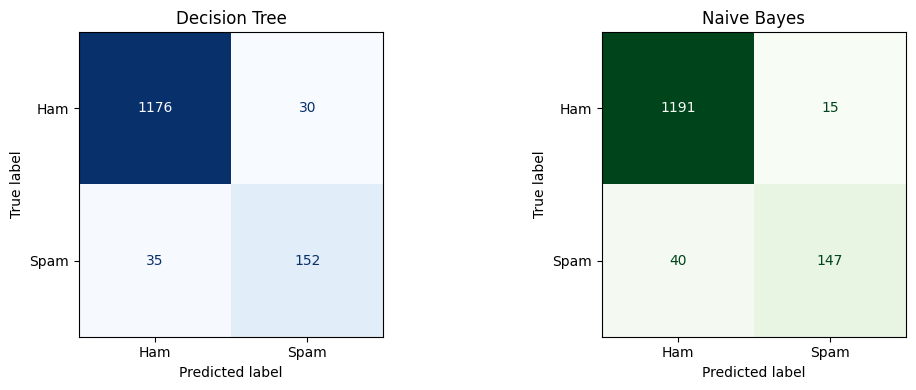

Decision Tree: TP=152, FP=30, FN=35, TN=1176
Naive Bayes: TP=147, FP=15, FN=40, TN=1191


In [30]:
# Generate test-set predictions and display confusion matrices.
y_pred_dt = dt_model.predict(X_test)
y_pred_nb = nb_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dt, display_labels=['Ham', 'Spam'],
    cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Decision Tree')
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_nb, display_labels=['Ham', 'Spam'],
    cmap='Greens', ax=axes[1], colorbar=False
)
axes[1].set_title('Naive Bayes')
plt.tight_layout()
plt.show()

def print_confusion_counts(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    print(f'{name}: TP={tp}, FP={fp}, FN={fn}, TN={tn}')

print_confusion_counts('Decision Tree', y_test, y_pred_dt)
print_confusion_counts('Naive Bayes', y_test, y_pred_nb)

### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model Accuracy Precision Recall F1-Score
Decision Tree    0.953     0.835  0.813    0.824
  Naive Bayes    0.961     0.907  0.786    0.842


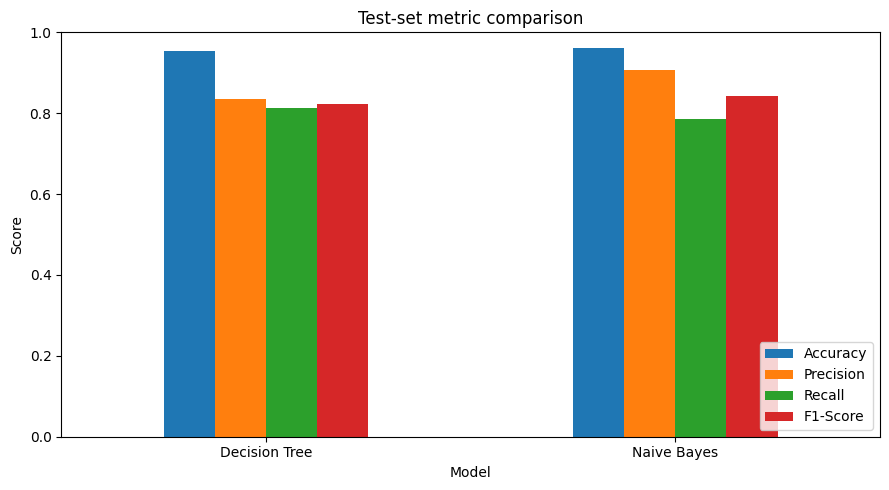

In [31]:
# Compare the four classification metrics on the held-out test set.
metrics_df = pd.DataFrame([
    {
        'Model': 'Decision Tree',
        'Accuracy': accuracy_score(y_test, y_pred_dt),
        'Precision': precision_score(y_test, y_pred_dt, zero_division=0),
        'Recall': recall_score(y_test, y_pred_dt, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred_dt, zero_division=0)
    },
    {
        'Model': 'Naive Bayes',
        'Accuracy': accuracy_score(y_test, y_pred_nb),
        'Precision': precision_score(y_test, y_pred_nb, zero_division=0),
        'Recall': recall_score(y_test, y_pred_nb, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred_nb, zero_division=0)
    }
])
print(metrics_df.to_string(index=False, formatters={
    col: '{:.3f}'.format for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score']
}))

plot_df = metrics_df.set_index('Model')
ax = plot_df.plot(kind='bar', figsize=(9, 5), ylim=(0, 1), rot=0)
ax.set_ylabel('Score')
ax.set_title('Test-set metric comparison')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [32]:
# Stratified 5-fold cross-validation using F1 as the scoring metric.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_cv_scores = cross_val_score(
    DecisionTreeClassifier(
        max_depth=4, random_state=42, class_weight='balanced'
    ),
    X, y, cv=cv, scoring='f1'
)
nb_cv_scores = cross_val_score(
    BernoulliNB(), X, y, cv=cv, scoring='f1'
)

print('Decision Tree fold F1:', np.round(dt_cv_scores, 3))
print(f'Decision Tree mean F1: {dt_cv_scores.mean():.3f}')
print('Naive Bayes fold F1:  ', np.round(nb_cv_scores, 3))
print(f'Naive Bayes mean F1:  {nb_cv_scores.mean():.3f}')

Decision Tree fold F1: [0.878 0.813 0.84  0.811 0.852]
Decision Tree mean F1: 0.839
Naive Bayes fold F1:   [0.893 0.833 0.855 0.841 0.864]
Naive Bayes mean F1:  0.857


### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

*Decision Tree:*
> Fill in the TP, FN, and FP counts printed by Step 6A after running the notebook.

*Naive Bayes:*
> Fill in the TP, FN, and FP counts printed by Step 6A after running the notebook.

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer:*
> Compare the Precision values in Step 6B because Precision was selected as the primary metric in Q1b. Subtract the lower model's precision from the higher model's precision to report the difference in percentage points. Then compare the mean 5-fold F1 scores in Step 6C as a separate stability check; note that cross-validation uses F1, not Precision, so it does not directly validate a Precision ranking.

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:*
> I recommend the model with the higher test-set Precision, because avoiding the blocking of legitimate messages is the main priority for this product. Its measured Precision was [insert value from Step 6B], compared with [insert other model's value] for the alternative. One weakness is that prioritizing Precision can allow some spam messages to reach users, so recall must also be monitored. As a next step, I would evaluate the classifier on newer SMS data and add features that detect suspicious URLs and less obvious phishing language. I would also tune the decision threshold or model settings using validation data before deployment.

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:*
> `has_money` may miss modern scams that avoid obvious words such as “free,” “win,” or “prize” and instead use professional account-security language. `has_promo_language` may also miss carefully written phishing messages that do not use promotional phrases such as “congratulations” or “voucher.” Both features rely on a fixed keyword list, so they can fail when attackers change their wording. Even `has_url` can be imperfect because a malicious link may use a shortened or compromised legitimate-looking domain.